# Sistema A.D.P. | Colônia de Marte
**FIAP · Ciência da Computação · Etapa 3 · Missão Aurora · 2026**

Este notebook reúne, com explicações, o mesmo código do arquivo `sistema_adp.py`. O **Sistema A.D.P. (Análise, Decisão e Previsão)** simula o acompanhamento energético de uma colônia em Marte:

1. **Organizar** os dados da colônia (listas, dicionários e hierarquia de sistemas);
2. **Analisar** geração e consumo de energia;
3. **Decidir** automaticamente com regras lógicas e prioridades;
4. **Prever** a geração eólica com regressão linear simples.

**Como usar:** execute as células em ordem (*Run All*). As seções 6 e 7 mostram demonstrações prontas, sem precisar digitar nada. Na seção 8 há o menu interativo, igual ao do terminal.

> Requisitos: Python 3, NumPy e matplotlib (`pip install numpy matplotlib`).

## 1. Importações e constantes
O programa usa apenas o **NumPy**, para a regressão linear (`np.polyfit`). O **matplotlib** é importado só quando o gráfico é aberto.

As regras de decisão têm limites fixos. Em vez de espalhar os números `50` e `70` pelo código, eles ficam em constantes no topo: assim ficam fáceis de achar, de explicar e de alterar.

In [ ]:
import numpy as np

LARGURA = 56

# ========== CONSTANTES DAS REGRAS DE DECISÃO ==========
LIMITE_ENERGIA = 50          # energia abaixo disso = reserva baixa
LIMITE_CONSUMO_ALTO = 70     # consumo acima disso = consumo alto

## 2. Organização dos dados
Três estruturas guardam as informações da colônia:

- **Duas listas** (`vento_historico` e `energia_historico`) formam o histórico da regressão. A posição `i` das duas listas é a mesma observação: vento de 8 km/h gerou 20 unidades de energia eólica, e assim por diante.
- **Um dicionário hierárquico** (`sistemas`): a chave `energetico` contém outro dicionário com `solar` e `eolico`. As demais chaves são sistemas simples (ligado/desligado).
- **Um dicionário chave-valor** (`dados`) com os valores informados pelo usuário. A geração total é a soma de solar e eólica.

As tuplas `ESSENCIAIS` e `ORDEM_CORTE` definem a **prioridade**: o que é essencial nunca é desligado, e o que é menos importante (lazer) é cortado antes da iluminação.

In [ ]:
# ========== DADOS ==========
# Histórico para a regressão linear: vento x geração EÓLICA
vento_historico = [8.0, 10.0, 12.0]
energia_historico = [20.0, 25.0, 30.0]

# Hierarquia e estado inicial dos sistemas da colônia
sistemas = {
    "energetico": {"solar": True, "eolico": True},
    "suporte_vida": True,
    "iluminacao": True,
    "lazer": True,
}

# Sistemas essenciais nunca são desligados pelo modo economia
ESSENCIAIS = ("energetico", "suporte_vida")
# Ordem de corte: o que é menos importante é desligado primeiro
ORDEM_CORTE = ("lazer", "iluminacao")

# Dados atuais da colônia (chave-valor)
dados = {
    "energia": 0.0,
    "solar": 0.0,
    "eolica": 0.0,
    "geracao": 0.0,   # solar + eólica
    "consumo": 0.0,
    "vento": 0.0,
}

## 3. Lógica: análise, decisão e previsão
A lógica fica separada da exibição: as funções abaixo só calculam e **retornam** resultados, sem imprimir nada na tela.

### 3.1 `analisar_energia`
Compara geração e consumo e devolve uma de três situações: `alerta` (consumo maior), `sobra` (geração maior) ou `equilibrio`.

In [ ]:
def analisar_energia(gerac: float, cons: float) -> str:
    if cons > gerac:
        return "alerta"
    elif gerac > cons:
        return "sobra"
    return "equilibrio"

### 3.2 `decidir`
Aplica as regras **em ordem de prioridade**; a primeira que for verdadeira vale:

1. **Energia < 50 E consumo > 70** → *modo economia*: desliga lazer e depois iluminação (sistemas não essenciais). Suporte à vida e sistema energético nunca são tocados.
2. **Energia < 50** → recomenda reduzir o consumo.
3. **Consumo > geração** (com energia normal) → *déficit*: a reserva está sendo gasta.
4. **Caso contrário** → operação normal, e os sistemas que foram desligados pelo modo economia são **religados**.

A função retorna uma tupla `(resultado, sistemas_alterados)`, e altera o dicionário `sistemas`.

In [ ]:
def decidir(energ: float, cons: float, gerac: float):
    # Regras em ordem de prioridade. Retorna (resultado, sistemas_alterados).
    # 1) Energia baixa E consumo alto -> modo economia (corta o não essencial)
    if energ < LIMITE_ENERGIA and cons > LIMITE_CONSUMO_ALTO:
        desligados = []
        for nome in ORDEM_CORTE:
            if sistemas[nome]:
                sistemas[nome] = False
                desligados.append(nome)
        return "economia", desligados

    # 2) Energia baixa -> reduzir consumo
    if energ < LIMITE_ENERGIA:
        return "reduzir", []

    # 3) Energia ok, mas consumo maior que a geração -> reserva sendo gasta
    if cons > gerac:
        return "deficit", []

    # 4) Situação normalizada -> religa o que foi cortado (do mais importante)
    religados = []
    for nome in reversed(ORDEM_CORTE):
        if not sistemas[nome]:
            sistemas[nome] = True
            religados.append(nome)
    return "normal", religados

### 3.3 `calcular_previsao`
Usa `np.polyfit(x, y, 1)` para ajustar uma reta `energia = a × vento + b` aos pares do histórico, e usa essa reta para estimar a energia eólica de um vento qualquer.

Cuidados da função:
- precisa de pelo menos 2 pontos e de pelo menos 2 valores de vento diferentes (senão não existe reta);
- a previsão nunca fica abaixo de zero (`max(0.0, ...)`).

Com o histórico inicial `[8, 10, 12] → [20, 25, 30]`, a reta é `energia = 2,5 × vento`, e vento = 11 resulta em **27,5**.

In [ ]:
def calcular_previsao(vento_alvo: float):
    # Regressão linear simples (reta y = ax + b). Retorna (a, b, previsao).
    if len(vento_historico) < 2 or len(set(vento_historico)) < 2:
        return None
    a, b = np.polyfit(vento_historico, energia_historico, 1)
    return a, b, max(0.0, a * vento_alvo + b)

## 4. Exibição (visual do terminal)
Estas funções só **mostram** informações. As mensagens usam marcadores de texto (`[OK]`, `[ALERTA]`, `[SUGESTÃO]`, `[ERRO]`), sem cores, e as barras `████░░░░` permitem comparar valores rapidamente.

### 4.1 Funções de formatação

In [ ]:
def titulo(texto: str) -> None:
    print()
    print("╔" + "═" * LARGURA + "╗")
    print("║" + texto.center(LARGURA) + "║")
    print("╚" + "═" * LARGURA + "╝")


def secao(texto: str) -> None:
    print()
    print(f"── {texto} " + "─" * (LARGURA - len(texto) - 4))


def linha(rotulo: str, valor: str) -> None:
    print(f"  {rotulo:<26}{valor:>12}")


def barra(valor: float, maximo: float, largura: int = 24) -> str:
    proporcao = 0 if maximo <= 0 else min(valor / maximo, 1)
    cheio = int(proporcao * largura)
    return "█" * cheio + "░" * (largura - cheio)


def pausar() -> None:
    input("\n  Pressione ENTER para voltar ao menu...")


def nomes(lista) -> str:
    return ", ".join(n.replace("iluminacao", "iluminação") for n in lista)

### 4.2 Telas de dados, análise e decisão
Cada tela chama a função de lógica correspondente e traduz o resultado em mensagens.

In [ ]:
def mostrar_dados() -> None:
    secao("Dados cadastrados")
    linha("Energia disponível", f"{dados['energia']:.1f}")
    linha("Geração solar", f"{dados['solar']:.1f}")
    linha("Geração eólica", f"{dados['eolica']:.1f}")
    linha("Geração total", f"{dados['geracao']:.1f}")
    linha("Consumo atual", f"{dados['consumo']:.1f}")
    linha("Vento (km/h)", f"{dados['vento']:.1f}")


def mostrar_analise() -> None:
    s, w = dados["solar"], dados["eolica"]
    g, c = dados["geracao"], dados["consumo"]
    secao("Análise de energia")
    maximo = max(g, c, 1)
    print(f"  Solar     {barra(s, maximo)}  {s:.1f}")
    print(f"  Eólica    {barra(w, maximo)}  {w:.1f}")
    print(f"  Geração   {barra(g, maximo)}  {g:.1f}")
    print(f"  Consumo   {barra(c, maximo)}  {c:.1f}")
    print()
    resultado = analisar_energia(g, c)
    if resultado == "alerta":
        print("  [ALERTA] Consumo maior que geração!")
    elif resultado == "sobra":
        print("  [SUGESTÃO] Armazenar energia excedente!")
    else:
        print("  [OK] Equilíbrio entre geração e consumo!")


def mostrar_decisao() -> None:
    e, c, g = dados["energia"], dados["consumo"], dados["geracao"]
    secao("Decisão automática")
    print(f"  Energia   {barra(e, 100)}  {e:.1f}  (baixa: abaixo de {LIMITE_ENERGIA})")
    print(f"  Consumo   {barra(c, 100)}  {c:.1f}  (alto: acima de {LIMITE_CONSUMO_ALTO})")
    print(f"  Geração   {barra(g, 100)}  {g:.1f}")
    print()
    resultado, alterados = decidir(e, c, g)
    if resultado == "economia":
        print("  [ALERTA] Modo de economia ativado!")
        if alterados:
            print(f"           Sistemas desligados: {nomes(alterados)}")
        else:
            print("           Sistemas não essenciais já estavam desligados.")
        print("           Suporte à vida mantido ligado.")
    elif resultado == "reduzir":
        print("  [ALERTA] Energia baixa. Recomenda-se reduzir o consumo.")
    elif resultado == "deficit":
        print("  [ATENÇÃO] Consumo maior que a geração: a reserva está sendo gasta.")
        print("            Recomenda-se reduzir o consumo.")
    else:
        print("  [OK] Operação normal.")
        if alterados:
            print(f"       Sistemas religados: {nomes(alterados)}")

### 4.3 Previsão e gráfico
`mostrar_previsao` pede o vento, mostra a tabela do histórico, a equação da reta e a previsão. Em seguida, `abrir_grafico` desenha com o **matplotlib**: pontos do histórico (azul), reta de ajuste (vermelho) e previsão (verde, marcador X). No notebook, o gráfico aparece dentro da própria célula.

In [ ]:
def mostrar_previsao() -> None:
    secao("Previsão de geração eólica")
    try:
        v = ler_float("Velocidade do vento para prever (km/h)")
    except ValueError:
        print("  [ERRO] Digite apenas números válidos.")
        return
    if v < 0:
        print("  [ERRO] A velocidade do vento não pode ser negativa.")
        return

    resultado = calcular_previsao(v)
    if resultado is None:
        print("  [ALERTA] Dados insuficientes para calcular previsão.")
        return
    a, b, previsao = resultado

    print("\n  Histórico (vento x geração eólica):")
    print("  ┌─────┬──────────────┬──────────┐")
    print("  │  #  │ Vento (km/h) │ Energia  │")
    print("  ├─────┼──────────────┼──────────┤")
    for i, (vh, eh) in enumerate(zip(vento_historico, energia_historico), 1):
        print(f"  │ {i:>3} │ {vh:>12.1f} │ {eh:>8.1f} │")
    print("  └─────┴──────────────┴──────────┘")

    print(f"\n  Modelo: energia = {a:.3f} x vento + {b:.3f}")
    print(f"  Vento informado: {v:.1f} km/h")
    print(f"\n  >> Previsão: {previsao:.2f} unidades de energia eólica")

    print("\n  Abrindo gráfico... (feche a janela para voltar ao menu)")
    abrir_grafico(a, b, v, previsao)


def abrir_grafico(a: float, b: float, v: float, previsao: float) -> None:
    try:
        import matplotlib.pyplot as plt
    except ImportError:
        print("  [ALERTA] matplotlib não instalado (pip install matplotlib).")
        return
    plt.scatter(vento_historico, energia_historico, color="blue", label="Histórico")
    x_plot = np.linspace(min(vento_historico + [v]) - 2, max(vento_historico + [v]) + 2, 100)
    plt.plot(x_plot, a * x_plot + b, color="red", label="Ajuste Linear")
    plt.scatter(v, previsao, color="green", marker="X", s=100, label="Previsão")
    plt.xlabel("Velocidade do Vento (km/h)")
    plt.ylabel("Energia Eólica Gerada")
    plt.title("Regressão Linear: Vento vs Energia Eólica")
    plt.legend()
    plt.grid(True)
    plt.show()

### 4.4 Hierarquia dos sistemas
`imprimir_arvore` é **recursiva**: quando o valor de uma chave é outro dicionário (como `energetico`), ela chama a si mesma para desenhar os subsistemas com um nível a mais de recuo.

In [ ]:
def imprimir_arvore(estrutura: dict, prefixo: str = "") -> None:
    # Percorre a hierarquia de forma recursiva, desenhando uma árvore.
    itens = list(estrutura.items())
    for i, (nome, valor) in enumerate(itens):
        ultimo = i == len(itens) - 1
        ramo = "└── " if ultimo else "├── "
        if isinstance(valor, dict):
            print(f"  {prefixo}{ramo}{nome}")
            imprimir_arvore(valor, prefixo + ("    " if ultimo else "│   "))
        else:
            status = "[LIGADO]   " if valor else "[DESLIGADO]"
            marca = "  (essencial)" if nome in ESSENCIAIS else ""
            print(f"  {prefixo}{ramo}{nome:<14} {status}{marca}")


def mostrar_sistemas() -> None:
    secao("Estado dos sistemas da colônia")
    print("  colônia")
    imprimir_arvore(sistemas)


def mostrar_menu() -> None:
    titulo("SISTEMA A.D.P  -  COLÔNIA DE MARTE")
    print("   [1]  Cadastrar dados")
    print("   [2]  Analisar energia da colônia")
    print("   [3]  Decidir (regras automáticas)")
    print("   [4]  Prever geração eólica")
    print("   [5]  Mostrar sistemas")
    print("   [0]  Sair")
    print("  " + "─" * LARGURA)

## 5. Entrada de dados
`ler_float` aceita vírgula ou ponto decimal. `cadastrar_dados` valida a entrada:
- texto que não é número → `[ERRO]` (tratado com `try/except ValueError`);
- valores negativos → `[ERRO]`, pois grandezas físicas não podem ser negativas.

**Detalhe importante:** antes de acrescentar o novo ponto ao histórico, o programa calcula a previsão do modelo para aquele vento e a compara com o valor observado (*verificação do modelo*). Assim a previsão nunca usa o próprio dado que está sendo testado.

In [ ]:
def ler_float(mensagem: str) -> float:
    return float(input(f"  {mensagem}: ").replace(",", "."))


def cadastrar_dados() -> bool:
    secao("Cadastro de dados")
    try:
        e = ler_float("Energia disponível")
        s = ler_float("Geração solar")
        w = ler_float("Geração eólica")
        c = ler_float("Consumo atual")
        v = ler_float("Velocidade do vento (km/h)")
    except ValueError:
        print("  [ERRO] Digite apenas números válidos.")
        return False

    if min(e, s, w, c, v) < 0:
        print("  [ERRO] Os valores físicos não podem ser negativos.")
        return False

    # Previsão feita ANTES de incluir o novo ponto no histórico,
    # para comparar o que o modelo previa com o que foi observado.
    anterior = calcular_previsao(v)

    dados.update(energia=e, solar=s, eolica=w, geracao=s + w, consumo=c, vento=v)

    # Alimenta o modelo com o novo dado (histórico contínuo)
    vento_historico.append(v)
    energia_historico.append(w)

    print("  [OK] Dados cadastrados e histórico atualizado com sucesso!")
    if anterior is not None:
        previsto = anterior[2]
        print(f"\n  Verificação do modelo (antes deste registro):")
        linha("Eólica prevista", f"{previsto:.1f}")
        linha("Eólica observada", f"{w:.1f}")
        linha("Diferença", f"{abs(w - previsto):.1f}")
    return True

## 6. Demonstração 1: previsão (sem digitar nada)
Chamamos `calcular_previsao` diretamente, com o histórico inicial. Resultado esperado: **27,5** para vento = 11 km/h.

Modelo: energia = 2.500 x vento + 0.000
Previsão para vento = 11 km/h: 27.50 unidades


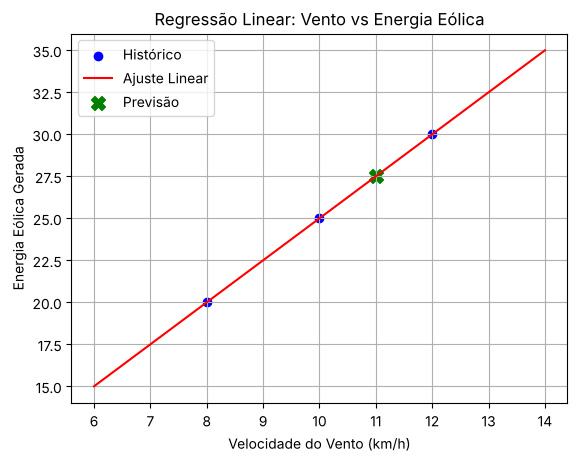

In [ ]:
resultado = calcular_previsao(11)
a, b, previsao = resultado
print(f"Modelo: energia = {a:.3f} x vento + {b:.3f}")
print(f"Previsão para vento = 11 km/h: {previsao:.2f} unidades")
abrir_grafico(a, b, 11, previsao)

## 7. Demonstração 2: cenários de decisão
Em vez de digitar no menu, preenchemos o dicionário `dados` diretamente e chamamos as telas.

### 7.1 Estado inicial dos sistemas

In [ ]:
mostrar_sistemas()


── Estado dos sistemas da colônia ──────────────────────
  colônia
  ├── energetico
  │   ├── solar          [LIGADO]   
  │   └── eolico         [LIGADO]   
  ├── suporte_vida   [LIGADO]     (essencial)
  ├── iluminacao     [LIGADO]   
  └── lazer          [LIGADO]   


### 7.2 Cenário crítico: energia = 40, geração = 30, consumo = 80
Energia abaixo de 50 **e** consumo acima de 70: o sistema entra em **modo economia** e desliga lazer e iluminação, mantendo o suporte à vida.

In [ ]:
dados.update(energia=40, solar=10, eolica=20, geracao=30, consumo=80, vento=11)
mostrar_dados()
mostrar_analise()
mostrar_decisao()
mostrar_sistemas()


── Dados cadastrados ───────────────────────────────────
  Energia disponível                40.0
  Geração solar                     10.0
  Geração eólica                    20.0
  Geração total                     30.0
  Consumo atual                     80.0
  Vento (km/h)                      11.0

── Análise de energia ──────────────────────────────────
  Solar     ███░░░░░░░░░░░░░░░░░░░░░  10.0
  Eólica    ██████░░░░░░░░░░░░░░░░░░  20.0
  Geração   █████████░░░░░░░░░░░░░░░  30.0
  Consumo   ████████████████████████  80.0

  [ALERTA] Consumo maior que geração!

── Decisão automática ──────────────────────────────────
  Energia   █████████░░░░░░░░░░░░░░░  40.0  (baixa: abaixo de 50)
  Consumo   ███████████████████░░░░░  80.0  (alto: acima de 70)
  Geração   ███████░░░░░░░░░░░░░░░░░  30.0

  [ALERTA] Modo de economia ativado!
           Sistemas desligados: lazer, iluminação
           Suporte à vida mantido ligado.

── Estado dos sistemas da colônia ──────────────────────
  colôni

### 7.3 Situação normalizada: energia = 70, geração = 70, consumo = 50
Com a energia recuperada, a decisão volta ao normal e os sistemas desligados pela economia são **religados**.

In [ ]:
dados.update(energia=70, solar=40, eolica=30, geracao=70, consumo=50, vento=10)
mostrar_decisao()
mostrar_sistemas()


── Decisão automática ──────────────────────────────────
  Energia   ████████████████░░░░░░░░  70.0  (baixa: abaixo de 50)
  Consumo   ████████████░░░░░░░░░░░░  50.0  (alto: acima de 70)
  Geração   ████████████████░░░░░░░░  70.0

  [OK] Operação normal.
       Sistemas religados: iluminação, lazer

── Estado dos sistemas da colônia ──────────────────────
  colônia
  ├── energetico
  │   ├── solar          [LIGADO]   
  │   └── eolico         [LIGADO]   
  ├── suporte_vida   [LIGADO]     (essencial)
  ├── iluminacao     [LIGADO]   
  └── lazer          [LIGADO]   


### 7.4 Excedente de energia: geração = 80, consumo = 30
A análise sugere armazenar o excedente.

In [ ]:
dados.update(energia=80, solar=50, eolica=30, geracao=80, consumo=30, vento=9)
mostrar_analise()


── Análise de energia ──────────────────────────────────
  Solar     ███████████████░░░░░░░░░  50.0
  Eólica    █████████░░░░░░░░░░░░░░░  30.0
  Geração   ████████████████████████  80.0
  Consumo   █████████░░░░░░░░░░░░░░░  30.0

  [SUGESTÃO] Armazenar energia excedente!


## 8. Programa completo (menu interativo)
A função `main` mostra o menu em repetição até o usuário escolher `0 - Sair`. Ela exige o cadastro (opção 1) antes das opções 2 e 3; as opções 4 e 5 funcionam a qualquer momento.

In [ ]:
# ========== MAIN ==========
def main():
    dados_cadastrados = False

    while True:
        mostrar_menu()
        opcao = input("  Escolha uma opção: ").strip()

        if opcao == "0":
            print("\n  Encerrando o sistema A.D.P... Até logo!\n")
            break
        elif opcao == "1":
            if cadastrar_dados():
                dados_cadastrados = True
                mostrar_dados()
        elif opcao in ("2", "3"):
            if not dados_cadastrados:
                print("  [ALERTA] Cadastre os dados primeiro (opção 1).")
            elif opcao == "2":
                mostrar_analise()
            else:
                mostrar_decisao()
        elif opcao == "4":
            mostrar_previsao()
        elif opcao == "5":
            mostrar_sistemas()
        else:
            print("  [ALERTA] Opção inválida.")

        pausar()


main()

## 9. Resumo
| Requisito da atividade | Onde está no código |
| --- | --- |
| Organizar dados (listas e chave-valor) | `vento_historico`, `energia_historico`, `dados` |
| Hierarquia de sistemas | `sistemas` e `imprimir_arvore` |
| Regras de decisão com prioridade | `decidir`, `ESSENCIAIS`, `ORDEM_CORTE` |
| Análise de energia | `analisar_energia` |
| Previsão com regressão | `calcular_previsao` e `abrir_grafico` |
| Código organizado em funções | lógica, exibição e entrada separadas |